In [1]:
import torch
import torch.nn.functional as F
from torch import nn

import numpy as np

from xformers.ops.fmha import AttentionBias
import xformers.ops as xops

import matplotlib.pyplot as plt

from unakin.llm.tokenizers.llama_tokenizer import LlamaTokenizer

In [2]:
tokenizer = LlamaTokenizer(model_path="/mnt/raid0/llamas/codellama/CodeLlama-13b-Instruct/tokenizer.model")
sentence = "def add(a: int, b: int) -> int:"
tokens = tokenizer.tokenize(sentence, bos=True, eos=False)
tokens = [torch.tensor(t, device="cuda") for t in tokens]
print(tokens)

[tensor([    1,   822,   788, 29898, 29874, 29901,   938, 29892,   289, 29901,
          938, 29897,  1599,   938, 29901], device='cuda:0')]


In [2]:
bs, seqlen, n_local_heads, head_dim = 2, 32, 12, 256

In [3]:
keys = torch.randn(bs, seqlen, n_local_heads, head_dim)
values = torch.randn(bs, seqlen, n_local_heads, head_dim)
xq = torch.randn(bs, seqlen, n_local_heads, head_dim)

In [23]:
# max_seq_len = max([len(t) for t in tokens])

mask = xops.fmha.attn_bias.BlockDiagonalCausalWithOffsetPaddedKeysMask.from_seqlens(
  q_seqlen=[16, 16],
  kv_seqlen=[16, 16],
  kv_padding=seqlen * bs,    
)

######################################################################
materialised = mask.materialize(shape=(2, 1, 32, seqlen * bs)).numpy()
materialised += 255
materialised[materialised == -np.inf] = 0
# print(materialised)
fig, ax = plt.subplots()  # Use plt.subplots() instead of plt.figure() to create a figure and axes
ax.imshow(materialised[0, 0], cmap='binary')  # Assuming you want to visualize the first channel of the mask
plt.show()

ValueError: k shapes wrong

In [ ]:
attn_output: torch.Tensor = xops.memory_efficient_attention(xq, keys, values, attn_bias=mask)

In [4]:
k_seqinfo = mask.k_seqinfo
q_seqinfo = mask.q_seqinfo

In [5]:
print(k_seqinfo)
print(q_seqinfo)

_PaddedSeqLenInfo(seqstart=tensor([ 0, 47], dtype=torch.int32), max_seqlen=15, min_seqlen=15, seqstart_py=[0, 47], seqlen=tensor([15], dtype=torch.int32), seqlen_py=[15], padding=47)
_SeqLenInfo(seqstart=tensor([ 0, 15], dtype=torch.int32), max_seqlen=15, min_seqlen=15, seqstart_py=[0, 15])


In [18]:
bsz = 1

q_seqinfo.seqstart.copy_(torch.arange(bsz + 1, dtype=torch.int))
q_seqinfo.min_seqlen = 1
q_seqinfo.max_seqlen = 1
q_seqinfo.seqstart_py = q_seqinfo.seqstart.tolist()

k_seqinfo.seqlen.add_(1)
k_seqinfo.seqlen_py = k_seqinfo.seqlen.tolist()


In [19]:
print(k_seqinfo)
print(q_seqinfo)

_PaddedSeqLenInfo(seqstart=tensor([ 0, 47], dtype=torch.int32), max_seqlen=15, min_seqlen=15, seqstart_py=[0, 47], seqlen=tensor([18], dtype=torch.int32), seqlen_py=[18], padding=47)
_SeqLenInfo(seqstart=tensor([0, 1], dtype=torch.int32), max_seqlen=1, min_seqlen=1, seqstart_py=[0, 1])


In [20]:
tokens

[tensor([    1,   822,   788, 29898, 29874, 29901,   938, 29892,   289, 29901,
           938, 29897,  1599,   938, 29901], device='cuda:0')]

In [21]:
tokens_new = [torch.tensor([-1])]

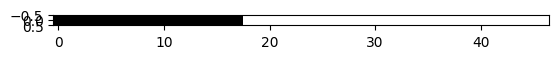

In [22]:
######################################################################
materialised = mask.materialize(shape=(1, 1, torch.cat(tokens_new).flatten().view(1, -1).shape[1], max_seq_len+32)).numpy()
materialised += 255
materialised[materialised == -np.inf] = 0
# print(materialised)
fig, ax = plt.subplots()  # Use plt.subplots() instead of plt.figure() to create a figure and axes
ax.imshow(materialised[0, 0], cmap='binary')  # Assuming you want to visualize the first channel of the mask
plt.show()